In [12]:
import pandas as pd
retail_2009=pd.read_excel('online_retail_II.xlsx', sheet_name=0)
retail_2010=pd.read_excel('online_retail_II.xlsx', sheet_name=1)
print(retail_2010.isnull().sum()) #check how many missing values exist in each column before deciding how to handle them
print(retail_2009.isnull().sum())
retail = pd.concat([retail_2009, retail_2010], ignore_index=True) #this loads both sheets into 1 dataframe
print(retail.shape)



Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64
(1067371, 8)


## Data Cleaning Pipeline

Cleans the combined dataset in four steps:

1. **Missing values** — drops rows with missing `Description` (~4,000 rows, negligible); flags missing `Customer ID` (~20-25% of rows) with `has_customer_id` rather than dropping, since these are still valid transactions for revenue analysis.
2. **Duplicate rows** — drops exact duplicates (identical Invoice, StockCode, Quantity, Price, InvoiceDate) confirmed to be accidental double entries, not genuine repeat purchases.
3. **Invalid prices** — drops rows with zero or negative prices, treated as data errors/adjustments rather than real sales.
4. **Cancelled orders** — flags invoices starting with `"C"` as `is_cancelled`, rather than dropping. Confirmed these are the same rows as negative quantities (19,103/19,103 match), so negative quantities didn't need a separate rule.

Cancelled orders are kept (not dropped) so they can be excluded from revenue totals later while still allowing return-pattern analysis if needed.

In [13]:
def handle_missing_values(dataframe):
    dataframe = dataframe.dropna(subset=['Description']).copy() #checks the discription column for nulls and drops any row where its missing(use subset to drop where descriptions are specifically null otherwise will drop Customer ID nulls too)
    dataframe['has_customer_id'] = dataframe['Customer ID'].notna() # Flag whether Customer ID exists rather than dropping these rows -
    return(dataframe)

retail=handle_missing_values(retail)

print(retail.shape) #around 4000 will be dropped from the total number of rows(the null descriptions )
invoice_as_text=retail['Invoice'].astype(str) #treat invoice as text
cancelled=invoice_as_text.str.startswith('C') #check which ones starts with C
print("Cancelled Invoices:",cancelled.sum()) #count how many invoices have been cancelled
negative_quantity=retail['Quantity']<0
print("Negative Quantities:", negative_quantity.sum())
negative_price=retail['Price']<=0
print("Zero/Negative Price:",negative_price.sum())
duplicate_rows=retail.duplicated()
print("Duplicated rows:",duplicate_rows.sum())

#Handling duplicated rows
def handling_duplicated_rows(dataframe):
    dataframe=dataframe.drop_duplicates().copy()
    return(dataframe)
retail=handling_duplicated_rows(retail)

#Handling Zero/negative prices

def remove_invalid_prices(dataframe):
    dataframe=dataframe[dataframe['Price']>0].copy()
    return(dataframe)
retail=remove_invalid_prices(retail)
print(retail.shape)

def flag_cancelled_orders(dataframe):
    dataframe = dataframe.copy() #ensures independent dataframe, avoids SettingWithCopyWarning
    dataframe['is_cancelled'] = dataframe['Invoice'].str.startswith('C') #flags invoices starting with 'C' as cancelled - these are the same rows as negative quantities, confirmed by earlier check
    return(dataframe)
retail = flag_cancelled_orders(retail)
print(retail['is_cancelled'].value_counts())


(1062989, 9)
Cancelled Invoices: 19494
Negative Quantities: 20261
Zero/Negative Price: 1825
Duplicated rows: 34228
(1027017, 9)
is_cancelled
True     19104
False        1
Name: count, dtype: int64


In [14]:
retail.to_csv('cleaned_retail_data.csv', index=False)

In [15]:
## Exploratory Data Analysis (EDA)
retail['Revenue']=retail['Quantity'] * retail['Price'] #total money value of each transaction line
summary = pd.DataFrame({
    'Metric': ['Earliest Date', 'Latest Date', 'Total Revenue', 'Unique Customers', 'Unique Products', 'Unique Countries'],
    'Value': [
        retail['InvoiceDate'].min(),
        retail['InvoiceDate'].max(),
        retail['Revenue'].sum(),
        retail['Customer ID'].nunique(),
        retail['StockCode'].nunique(),
        retail['Country'].nunique()
    ]
})
summary

,Metric,Value
0,Earliest Date,2009-12-01 07:45:00
1,Latest Date,2011-12-09 12:50:00
2,Total Revenue,19014209.838
3,Unique Customers,5939
4,Unique Products,4932
5,Unique Countries,43


In [16]:
## Monthly Revenue Trend
retail['YearMonth'] = retail['InvoiceDate'].dt.to_period('M')
monthly_revenue = retail.groupby('YearMonth')['Revenue'].sum()# Group by month and sum revenue
monthly_revenue

YearMonth
2009-12     796648.500
2010-01     622479.502
2010-02     531265.366
2010-03     763247.241
2010-04     641521.052
2010-05     613270.720
2010-06     677073.870
2010-07     617365.480
2010-08     654774.390
2010-09     851105.961
2010-10    1080611.480
2010-11    1416697.202
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     703510.580
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
2011-12     432719.060
Freq: M, Name: Revenue, dtype: float64

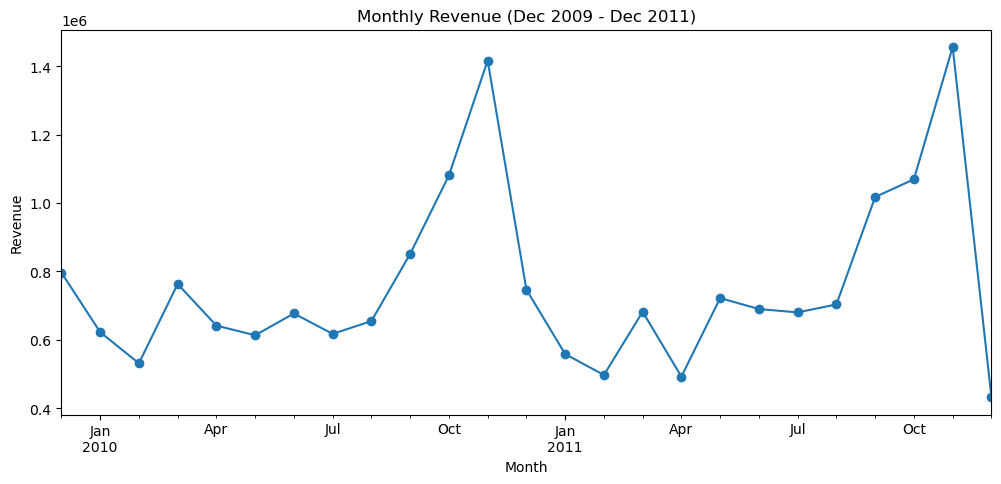

In [17]:
## Revenue Trend(Line Graph)
import matplotlib.pyplot as plt
monthly_revenue.plot(kind='line', figsize=(12,5), marker='o') 
plt.title('Monthly Revenue (Dec 2009 - Dec 2011)')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.show()

In [18]:
#Top 10 Products by quantity sold
top_products_qty = retail.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
print("Top 10 products by quantity sold:")
print(top_products_qty)
# Top 10 products by revenue generated .... focus on profit generating months 
top_products_revenue = retail.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)
print("Top 10 products by revenue:")
print(top_products_revenue)
# Top 10 Countries by revenue 
top_countries=retail.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)
print("Top 10 Countries by revenue:")
print(top_countries)

Top 10 products by quantity sold:
Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     104435
WHITE HANGING HEART T-LIGHT HOLDER     91021
ASSORTED COLOUR BIRD ORNAMENT          79571
JUMBO BAG RED RETROSPOT                76508
BROCADE RING PURSE                     69629
PACK OF 60 PINK PAISLEY CAKE CASES     55842
60 TEATIME FAIRY CAKE CASES            53678
SMALL POPCORN HOLDER                   48198
PACK OF 72 RETROSPOT CAKE CASES        47695
PACK OF 72 RETRO SPOT CAKE CASES       46079
Name: Quantity, dtype: int64
Top 10 products by revenue:
Description
REGENCY CAKESTAND 3 TIER               314045.02
DOTCOM POSTAGE                         309844.10
WHITE HANGING HEART T-LIGHT HOLDER     251603.12
PARTY BUNTING                          147079.73
JUMBO BAG RED RETROSPOT                145946.05
ASSORTED COLOUR BIRD ORNAMENT          128550.42
PAPER CHAIN KIT 50'S CHRISTMAS         116298.59
POSTAGE                                110430.41
CHILLI LIGHTS                           799

In [19]:
non_product_keywords = ['POSTAGE', 'DOTCOM POSTAGE', 'MANUAL', 'BANK CHARGES'] #these are shipping/admin charges recorded as line items, not real products - want to exclude them for an accurate "top products" view

real_products = retail[~retail['Description'].isin(non_product_keywords)] #keeps only rows where Description is NOT one of the non-product labels above (~ means "not")

top_real_products_revenue = real_products.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10) #recalculates top 10 products by revenue, now excluding postage/admin entries
print(top_real_products_revenue)

Description
REGENCY CAKESTAND 3 TIER               314045.02
WHITE HANGING HEART T-LIGHT HOLDER     251603.12
PARTY BUNTING                          147079.73
JUMBO BAG RED RETROSPOT                145946.05
ASSORTED COLOUR BIRD ORNAMENT          128550.42
PAPER CHAIN KIT 50'S CHRISTMAS         116298.59
CHILLI LIGHTS                           79905.13
ROTATING SILVER ANGELS T-LIGHT HLDR     70969.95
JUMBO BAG STRAWBERRY                    68489.89
RABBIT NIGHT LIGHT                      66661.63
Name: Revenue, dtype: float64


In [20]:
# Total revenue per customer (excluding rows with no Customer ID, since we can't attribute those)
customer_revenue = retail[retail['has_customer_id']].groupby('Customer ID')['Revenue'].sum().sort_values(ascending=False)
print(customer_revenue.describe())
# Quangtifying the 80/20 pattern
# What % of total revenue comes from the top 20% of customers?
num_customers = len(customer_revenue)
top_20_pct_count = int(num_customers * 0.2)
top_20_revenue = customer_revenue.head(top_20_pct_count).sum()
total_revenue = customer_revenue.sum()
percentage = top_20_revenue / total_revenue * 100
print("Top 20% of customers (", top_20_pct_count, "customers ) generate", round(percentage, 1), "% of total revenue")

count      5939.000000
mean       2742.884541
std       13679.955199
min      -25111.090000
25%         321.365000
50%         823.530000
75%        2143.280000
max      570380.610000
Name: Revenue, dtype: float64
Top 20% of customers ( 1187 customers ) generate 77.4 % of total revenue


## EDA Summary

Key findings from exploratory analysis:

- **Scope:** Dataset spans Dec 2009 - Dec 2011, ~£19M total revenue, 5,939 unique customers, 4,932 unique products, across 43 countries.
- **Seasonality:** Revenue rises sharply from September through November each year (peaking ~£1.4M in November), consistent with holiday shopping demand for this gift/homeware retailer.
- **Data quality note:** Initial "top products by revenue" included non-product entries ("POSTAGE", "DOTCOM POSTAGE") - these were filtered out to isolate genuine product performance.
- **Geographic concentration:** The UK accounts for ~85% of total revenue, with all other countries contributing comparatively small amounts.
- **Customer concentration:** Revenue is highly skewed - the top 20% of customers (1,187 people) generate 77.4% of total revenue, a near-textbook 80/20 pattern. This finding motivates the customer segmentation performed in the next phase.

In [21]:
top_months = monthly_revenue.sort_values(ascending=False).head(5)
print(top_months)
# Extract YearMonth as a string to filter easily (e.g. '2011-11')
best_month = top_months.index[0]
month_data = retail[retail['YearMonth'] == best_month]
top_products_best_month = month_data.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)
print(f"Top products in {best_month}:")
print(top_products_best_month)


YearMonth
2011-11    1456145.800
2010-11    1416697.202
2010-10    1080611.480
2011-10    1069368.230
2011-09    1017596.682
Freq: M, Name: Revenue, dtype: float64
Top products in 2011-11:
Description
DOTCOM POSTAGE                        36905.40
RABBIT NIGHT LIGHT                    34343.77
PAPER CHAIN KIT 50'S CHRISTMAS        28853.54
WHITE HANGING HEART T-LIGHT HOLDER    14339.32
POPCORN HOLDER                        13961.94
PAPER CHAIN KIT VINTAGE CHRISTMAS     12816.79
REGENCY CAKESTAND 3 TIER              12772.98
CHILLI LIGHTS                         11475.07
JUMBO BAG RED RETROSPOT               11456.13
HOT WATER BOTTLE KEEP CALM            11436.52
Name: Revenue, dtype: float64


In [30]:
retail['is_cancelled'] = retail['is_cancelled'].fillna(False).infer_objects(copy=False)
total_orders = retail['Invoice'].nunique()
cancelled_orders = retail[retail['is_cancelled']]['Invoice'].nunique()
cancellation_rate = cancelled_orders / total_orders * 100
print("Total unique orders:", total_orders)
print("Cancelled orders:", cancelled_orders)
print("Cancellation rate:", round(cancellation_rate, 2), "%")
# Get one row per unique invoice, keeping its country and cancelled status
invoice_level = retail.drop_duplicates(subset='Invoice')[['Invoice', 'Country', 'is_cancelled']]

# Now group by country at the invoice level (no double-counting line items)
country_cancellations = invoice_level.groupby('Country').agg(
    total_orders=('Invoice', 'nunique'),
    cancelled_orders=('is_cancelled', 'sum')
)
country_cancellations['cancellation_rate'] = country_cancellations['cancelled_orders'] / country_cancellations['total_orders'] * 100
country_cancellations = country_cancellations[country_cancellations['total_orders'] >= 50]
print(country_cancellations.sort_values('cancellation_rate', ascending=False).head(10))

Total unique orders: 48369
Cancelled orders: 8292
Cancellation rate: 17.14 %
                 total_orders  cancelled_orders  cancellation_rate
Country                                                           
Japan                      56                23          41.071429
Channel Islands            79                24          30.379747
Italy                      92                27          29.347826
Germany                  1095               306          27.945205
Switzerland               123                30          24.390244
Portugal                  124                29          23.387097
EIRE                      806               180          22.332506
Denmark                    53                10          18.867925
Australia                 117                22          18.803419
Sweden                    129                24          18.604651


In [ ]:
### RFM Feature engineering (Customer Feature Table (Recency, Frequency, Monetary)
### Building the RFM Table

import datetime as dt
# Reference date - one day after the last transaction in the dataset, standard convention for Recency
reference_date = retail['InvoiceDate'].max() + dt.timedelta(days=1)
rfm = retail[retail['has_customer_id']].groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Revenue', 'sum')
)
rfm.head()


Customers with negative Monetary: 84
             Recency  Frequency      Monetary
Customer ID                                  
12346.0          326         17 -5.174000e+01
12382.0          682          1 -1.838000e+01
12706.0          682          1 -9.189000e+01
12896.0          731          1 -2.975000e+01
12918.0          626          3 -1.095350e+04
...              ...        ...           ...
17661.0          641          1 -5.400000e+01
17755.0          424          1 -7.223000e+01
17943.0          680          1 -1.650300e+02
18023.0          540          1 -3.248860e+03
18072.0          155          2 -5.329071e-15

[84 rows x 3 columns]


In [ ]:

# Check how many customers have negative Monetary values
negative_monetary = rfm[rfm['Monetary'] < 0]
print("Customers with negative Monetary:", len(negative_monetary))
print(negative_monetary)
rfm['Monetary'] = rfm['Monetary'].round(2)
rfm['Monetary'] = rfm['Monetary'].round(2)

Customers with negative Monetary: 81
             Recency  Frequency  Monetary
Customer ID                              
12346.0          326         17    -51.74
12382.0          682          1    -18.38
12706.0          682          1    -91.89
12896.0          731          1    -29.75
12918.0          626          3 -10953.50
...              ...        ...       ...
17645.0          728          1     -9.90
17661.0          641          1    -54.00
17755.0          424          1    -72.23
17943.0          680          1   -165.03
18023.0          540          1  -3248.86

[81 rows x 3 columns]


In [ ]:
### Scaling Features for Clustering
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])

rfm_scaled = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'], index=rfm.index)
rfm_scaled.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,0.582001,0.591455,-0.204303
12347.0,-0.948397,0.027858,0.159272
12348.0,-0.603585,-0.160008,-0.052891
12349.0,-0.868098,-0.160008,0.121477
12350.0,0.506426,-0.410496,-0.176074


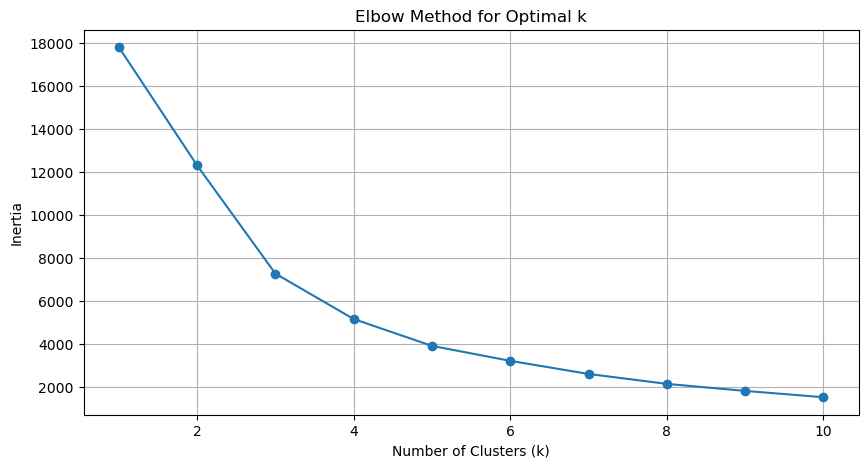

In [37]:
### Finding the Optimal Number of Clusters (Elbow Method)
### K-Means needs to be told how many clusters (`k`) to create - but the right number isn't o
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(k_range, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

### Running K-Means Clustering (k=4) and Interpreting Segments

Based on the elbow method, k=4 was chosen as the optimal number of clusters. K-Means is applied to the scaled RFM features, and each customer is assigned a cluster label (0-3).

To understand what each cluster represents in business terms, the average Recency, Frequency, and Monetary values are calculated per cluster, along with the number of customers in each group. This reveals four distinct segments:

- **Cluster 0 - At-Risk/Inactive:** high Recency, low Frequency and Monetary - customers who haven't purchased in a long time.
- **Cluster 1 - Regular/Core Customers:** moderate values across all three metrics - the bulk of the active customer base.
- **Cluster 2 - VIP/Whales:** an extremely small group (4 customers) with very recent, very frequent, and very high-value purchases - likely wholesale/business accounts.
- **Cluster 3 - High-Value Loyal:** a small but valuable group of frequent, recently active, high-spending customers.

In [39]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)
rfm.head()
cluster_summary = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()
cluster_summary['Count'] = rfm.groupby('Cluster').size()
print(cluster_summary)

            Recency   Frequency       Monetary  Count
Cluster                                              
0        466.064865    2.580835     607.083916   2035
1         66.106273    8.689995    2750.609057   3858
2          3.500000  257.000000  413886.007500      4
3         20.119048  120.571429   66361.469762     42


### Verifying Revenue Concentration in Top Clusters

Confirming how much of total revenue comes from Clusters 2 and 3 (the VIP and High-Value Loyal segments), tying this back to the earlier EDA finding that the top 20% of customers generate 77.4% of revenue.


In [41]:
cluster_revenue = rfm.groupby('Cluster')['Monetary'].sum()
total_revenue_rfm = rfm['Monetary'].sum()
cluster_revenue_pct = cluster_revenue / total_revenue_rfm * 100
print(cluster_revenue_pct)

Cluster
0     7.583895
1    65.143373
2    10.162952
3    17.109780
Name: Monetary, dtype: float64


### Visualizing Customer Segments

A scatter plot of Recency vs Monetary, colored by cluster, to visually show how the four segments differ.

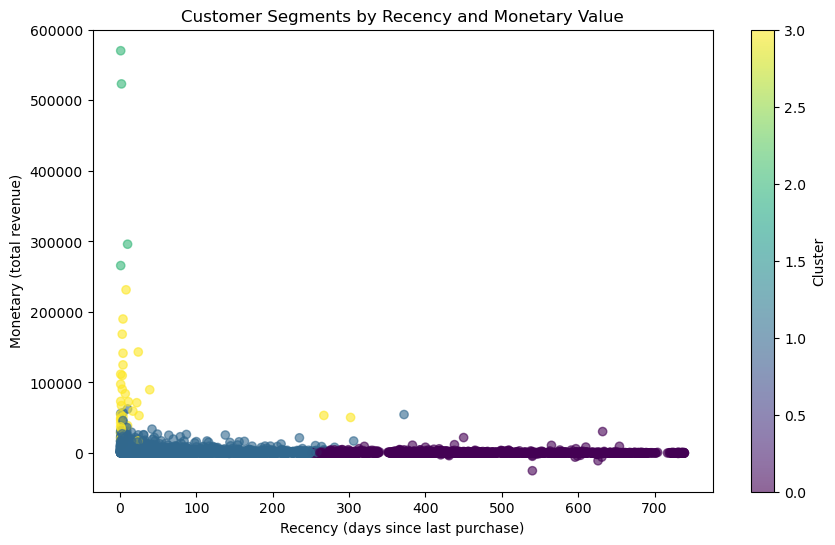

In [42]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(rfm['Recency'], rfm['Monetary'], c=rfm['Cluster'], cmap='viridis', alpha=0.6)
plt.xlabel('Recency (days since last purchase)')
plt.ylabel('Monetary (total revenue)')
plt.title('Customer Segments by Recency and Monetary Value')
plt.colorbar(scatter, label='Cluster')
plt.show()